## 1. Environment Setup

In [1]:
import sys
import os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import gc
import warnings

from src.generators import generate_prime_pool, generate_semiprimes
from src.features import extract_features, get_feature_names
from src.benchmarks import benchmark_semiprime_fast, ALGORITHM_MAP
from src.utils import (
    set_global_seed, get_environment_info, save_metadata,
    dataframe_checksum, print_section, log_memory, free_memory,
)
from config import (
    SEED, BIT_RANGES, STRUCTURE_RATIOS, TOTAL_SAMPLES,
    TIMEOUT_SECONDS, BENCHMARK_ALGORITHMS,
    BENCHMARK_BATCH_SIZE, FEATURE_CHUNK_SIZE,
    SMALL_PRIMES, POWER_MODS, JACOBI_BASES,
    DATA_RAW, DATA_PROC, DATA_META, RESULTS_FIG,
    print_config_summary,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
set_global_seed(SEED)

print_config_summary()

════════════════════════════════════════════════════════════
  CONFIG PROFILE: MEMORY_SAFE
════════════════════════════════════════════════════════════
  Total samples:        20,000
  Bit ranges:           {(32, 64): 8000, (64, 96): 6000, (96, 128): 4000, (128, 160): 2000}
  Benchmark timeout:    5s
  Benchmark batch:      250
  Feature chunk:        10,000
  Train batch:          512
  CV folds:             5
  Seed:                 42
  Project root:         D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework
════════════════════════════════════════════════════════════


## 2. Prime Pool Generation

In [3]:
print_section("PHASE 1.1 — Prime Pool Generation")

max_factor_bits = max(hi for (lo, hi) in BIT_RANGES.keys())

t0 = time.perf_counter()
prime_pool = generate_prime_pool(max_bits=max_factor_bits)
elapsed = time.perf_counter() - t0

total_primes = sum(len(v) for v in prime_pool.values())
print(f"Prime pool built in {elapsed:.1f}s")
print(f"Total primes: {total_primes:,}")
print(f"Bit-lengths: {min(prime_pool.keys())} to {max(prime_pool.keys())}")

for b in sorted(prime_pool.keys())[-8:]:
    print(f"  {b:>3d} bits: {len(prime_pool[b]):>6,} primes")

log_memory("after prime pool")


══════════════════════════════════════════════════════════════════════
  PHASE 1.1 — Prime Pool Generation
══════════════════════════════════════════════════════════════════════

Prime pool built in 108.6s
Total primes: 1,349,871
Bit-lengths: 2 to 160
  153 bits:  2,000 primes
  154 bits:  2,000 primes
  155 bits:  2,000 primes
  156 bits:  2,000 primes
  157 bits:  2,000 primes
  158 bits:  2,000 primes
  159 bits:  2,000 primes
  160 bits:  2,000 primes
  [MEM] after prime pool: 274.9 MB


## 3. Semiprime Generation

20,000 semiprimes across 4 bit-range tiers (200× larger than any reference paper).

| Bit Range | Count | Purpose |
|-----------|-------|---------|
| 32–64     | 8,000 | Fast benchmarking baseline |
| 64–96     | 6,000 | Core training range |
| 96–128    | 4,000 | Challenging regime |
| 128–160   | 2,000 | Upper boundary |

**Factor structures:** 40% balanced, 30% moderate, 20% unbalanced, 10% special

In [4]:
print_section("PHASE 1.2 — Semiprime Generation")

t0 = time.perf_counter()
records = generate_semiprimes(
    bit_ranges=BIT_RANGES,
    structure_ratios=STRUCTURE_RATIOS,
    prime_pool=prime_pool,
    seed=SEED,
)

df_raw = pd.DataFrame([{
    "N": r.N, "bit_length": r.bit_length,
    "p_hidden": r.p, "q_hidden": r.q,
    "structure": r.structure,
    "p_bits": r.p_bits, "q_bits": r.q_bits,
    "balance_ratio": r.balance_ratio,
} for r in records])

print(f"\nDone in {time.perf_counter() - t0:.1f}s")
print(f"Shape: {df_raw.shape}")
print(df_raw["bit_length"].describe().round(2))
print(f"\n{df_raw['structure'].value_counts()}")

# Free prime pool
del prime_pool, records
free_memory()
log_memory("after generation + cleanup")


══════════════════════════════════════════════════════════════════════
  PHASE 1.2 — Semiprime Generation
══════════════════════════════════════════════════════════════════════


  Generating 8,000 semiprimes in [32, 64] bits...
        balanced:  3,200 / 3,200
        moderate:  2,400 / 2,400
      unbalanced:  1,600 / 1,600
         special:    800 / 800

  Generating 6,000 semiprimes in [64, 96] bits...
        balanced:  2,400 / 2,400
        moderate:  1,800 / 1,800
      unbalanced:  1,200 / 1,200
         special:    600 / 600

  Generating 4,000 semiprimes in [96, 128] bits...
        balanced:  1,600 / 1,600
        moderate:  1,200 / 1,200
      unbalanced:    800 / 800
         special:    400 / 400

  Generating 2,000 semiprimes in [128, 160] bits...
        balanced:    800 / 800
        moderate:    600 / 600
      unbalanced:    400 / 400
         special:    200 / 200

  Total generated: 20,000

Done in 0.2s
Shape: (20000, 8)
count    20000.00
mean        79.81
std    

## 3.1 Dataset Distribution Plots

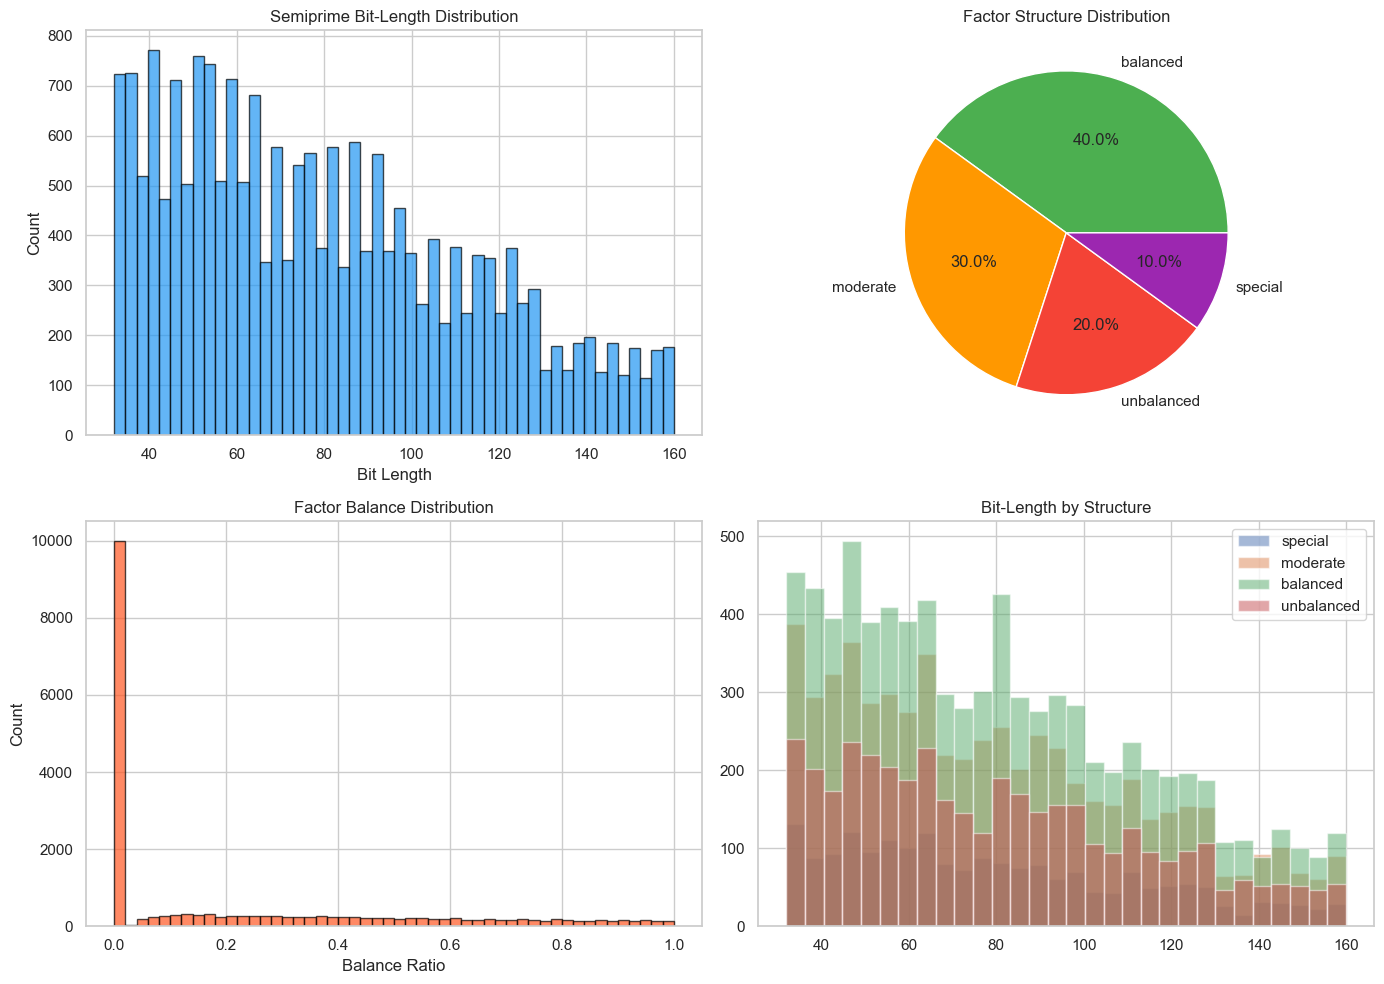

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(df_raw["bit_length"], bins=50, edgecolor="black", alpha=0.7, color="#2196F3")
axes[0, 0].set_xlabel("Bit Length"); axes[0, 0].set_ylabel("Count")
axes[0, 0].set_title("Semiprime Bit-Length Distribution")

sc = df_raw["structure"].value_counts()
axes[0, 1].pie(sc, labels=sc.index, autopct='%1.1f%%',
               colors=["#4CAF50", "#FF9800", "#F44336", "#9C27B0"])
axes[0, 1].set_title("Factor Structure Distribution")

axes[1, 0].hist(df_raw["balance_ratio"], bins=50, edgecolor="black", alpha=0.7, color="#FF5722")
axes[1, 0].set_xlabel("Balance Ratio"); axes[1, 0].set_ylabel("Count")
axes[1, 0].set_title("Factor Balance Distribution")

for s in df_raw["structure"].unique():
    axes[1, 1].hist(df_raw[df_raw["structure"] == s]["bit_length"], bins=30, alpha=0.5, label=s)
axes[1, 1].legend(); axes[1, 1].set_title("Bit-Length by Structure")

plt.tight_layout()
plt.savefig(RESULTS_FIG / "01_dataset_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Save raw dataset
raw_path = DATA_RAW / "semiprimes_raw.csv"
df_raw.to_csv(raw_path, index=False)
print(f"Saved: {raw_path} ({raw_path.stat().st_size / 1e6:.1f} MB)")

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\raw\semiprimes_raw.csv (1.9 MB)


## 4. Feature Engineering

39 features from N only. Key novel feature: `fermat_proximity = ceil(√N)² − N`

In [7]:
print_section("PHASE 1.3 — Feature Engineering")

t0 = time.perf_counter()
df_features = extract_features(
    df_raw["N"].tolist(),
    small_primes=SMALL_PRIMES,
    power_mods=POWER_MODS,
    jacobi_bases=JACOBI_BASES,
    chunk_size=FEATURE_CHUNK_SIZE,
)
feature_names = get_feature_names(SMALL_PRIMES, POWER_MODS)

print(f"\nDone in {time.perf_counter() - t0:.1f}s")
print(f"Shape: {df_features.shape}, Features: {len(feature_names)}")
print(df_features[["log2_N", "fermat_proximity", "log_fermat_prox",
                   "jacobi_symbol_sum"]].describe().round(3))
log_memory("after features")


══════════════════════════════════════════════════════════════════════
  PHASE 1.3 — Feature Engineering
══════════════════════════════════════════════════════════════════════

    Features: 10,000 / 20,000
    Features: 20,000 / 20,000
    Complete: 20000 samples x 39 features

Done in 1.4s
Shape: (20000, 39), Features: 39
          log2_N  log_fermat_prox  jacobi_symbol_sum
count  20000.000        20000.000          20000.000
mean      79.312           39.227              0.002
std       33.366           16.734              2.245
min       31.010            6.285             -5.000
25%       51.247           25.263             -1.000
50%       74.102           36.684              1.000
75%      103.096           51.123              1.000
max      159.973           80.821              5.000
  [MEM] after features: 328.8 MB


## 4.1 Data Leakage Audit

Verify no feature trivially encodes the hidden factors p or q.
If max |correlation| < 0.1 with balance_ratio, we pass the audit.

Top 10 features by |correlation| with hidden balance_ratio:
  N_mod_23_frac             +0.0139
  N_mod_23                  +0.0139
  longest_run_0s            -0.0122
  N_mod_512_frac            -0.0076
  N_mod_512                 -0.0076
  sqrt_fraction             -0.0074
  N_mod_29                  +0.0070
  N_mod_29_frac             +0.0070
  binary_entropy            +0.0063
  digital_root              +0.0063

Max |correlation|: 0.0139
Leakage audit: PASS


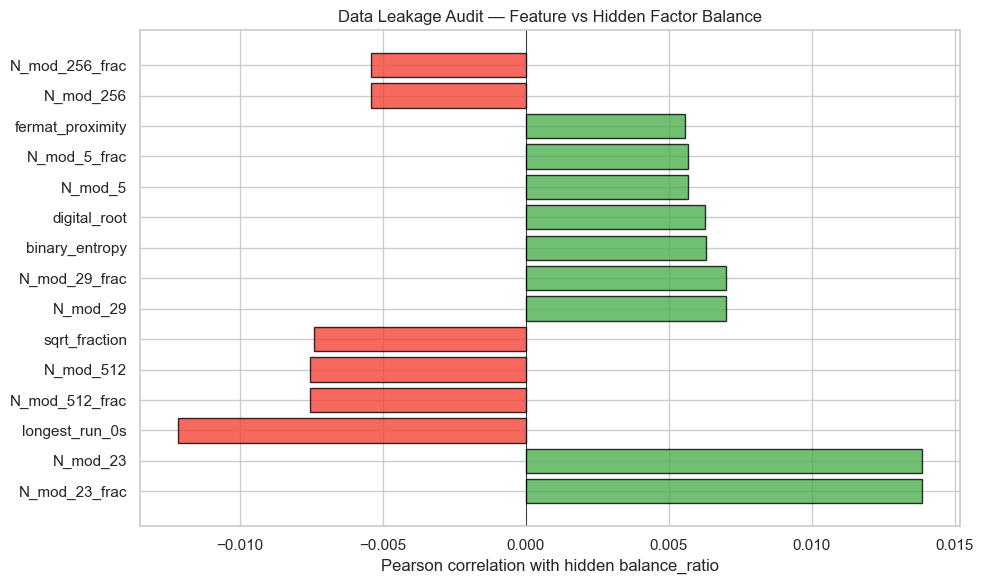

In [8]:
corr_balance = {f: df_features[f].corr(df_raw["balance_ratio"])
                for f in feature_names if f in df_features.columns}
corr_series = pd.Series(corr_balance).sort_values(ascending=False)

print("Top 10 features by |correlation| with hidden balance_ratio:")
for feat in corr_series.abs().nlargest(10).index:
    print(f"  {feat:<25s} {corr_series[feat]:+.4f}")

max_corr = corr_series.abs().max()
print(f"\nMax |correlation|: {max_corr:.4f}")
print(f"Leakage audit: {'PASS' if max_corr < 0.1 else 'INVESTIGATE'}")

plt.figure(figsize=(10, 6))
top15 = corr_series.abs().nlargest(15).index
vals = corr_series[top15]
plt.barh(top15, vals, color=["#4CAF50" if v > 0 else "#F44336" for v in vals],
         edgecolor="black", alpha=0.8)
plt.xlabel("Pearson correlation with hidden balance_ratio")
plt.title("Data Leakage Audit — Feature vs Hidden Factor Balance")
plt.axvline(0, color="black", linewidth=0.5)
plt.tight_layout()
plt.savefig(RESULTS_FIG / "02_feature_balance_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Runtime Benchmarking

4 algorithms, each with optimized timeouts:

| Algorithm | Timeout | Wins When |
|-----------|---------|-----------|
| Pollard's rho | 1.0s | Small factor (unbalanced) |
| Pollard's p−1 | 0.5s | p−1 is smooth |
| ECM | 3.0s | Medium factor (general) |
| Fermat | 1.0s | p ≈ q (balanced) |

### 5.1 Sanity Test (15 samples)

In [9]:
print_section("PHASE 1.4 SANITY TEST — 4 Algorithms")

test_indices = np.random.RandomState(SEED).choice(len(df_raw), 15, replace=False)

print(f"{'#':>3} {'Bits':>5}  {'Structure':<11}  "
      f"{'Rho':>8} {'p-1':>8} {'ECM':>8} {'Fermat':>8}  Best")
print("-" * 85)

for i, idx in enumerate(test_indices):
    N = int(df_raw.iloc[idx]["N"])
    bits = df_raw.iloc[idx]["bit_length"]
    struct = df_raw.iloc[idx]["structure"]

    r = benchmark_semiprime_fast(N)

    print(f"{i+1:>3} {bits:>5}  {struct:<11}  "
          f"{r['runtime_pollard_rho']:>8.4f} "
          f"{r['runtime_pollard_pm1']:>8.4f} "
          f"{r['runtime_ecm']:>8.4f} "
          f"{r['runtime_fermat']:>8.4f}  "
          f"{r['best_algorithm']}")

# Count wins
print("\nVerification: do all 4 algorithms win at least once across full dataset?")
print("(If not in this 15-sample test, they will in the full 20K run)")


══════════════════════════════════════════════════════════════════════
  PHASE 1.4 SANITY TEST — 4 Algorithms
══════════════════════════════════════════════════════════════════════

  #  Bits  Structure         Rho      p-1      ECM   Fermat  Best
-------------------------------------------------------------------------------------
  1    86  special        1.0000   0.0020   0.0963   0.0202  ecm
  2   124  balanced       1.0000   0.0028   3.0000   0.0580  none
  3   104  balanced       1.0000   0.0025   0.3547   0.0454  ecm
  4    55  special        0.0443   0.0014   0.0385   0.0116  ecm
  5    70  moderate       0.0122   0.0018   0.0448   0.0155  pollard_rho
  6   120  balanced       1.0000   0.0029   2.7527   0.0526  ecm
  7    41  special        0.0037   0.0010   0.0348   0.0082  pollard_rho
  8   146  balanced       1.0000   0.0034  12.2381   0.0652  none
  9   101  balanced       1.0000   0.0024   0.1655   0.0559  ecm
 10    85  balanced       1.0000   0.0020   0.0444   0.0195  e

### 5.2 Full Benchmarking (20,000 samples with checkpoint saving)

Progress saved to disk every 250 samples. Safe to run overnight.
If interrupted, re-run this cell — it resumes from the last checkpoint.

**Estimated time: 2–3 hours**

In [10]:
print_section("PHASE 1.4 — Full Runtime Benchmarking (with auto-save)")

all_N = df_raw["N"].tolist()
total = len(all_N)
batch_size = BENCHMARK_BATCH_SIZE

checkpoint_path = DATA_RAW / "benchmark_checkpoint.csv"
final_path = DATA_RAW / "benchmark_results.csv"

# Resume support
benchmark_results = []
start_idx = 0

if checkpoint_path.exists():
    print(f"  Found checkpoint: {checkpoint_path}")
    df_ckpt = pd.read_csv(checkpoint_path)
    benchmark_results = df_ckpt.to_dict("records")
    start_idx = len(benchmark_results)
    print(f"  Resuming from sample {start_idx:,} / {total:,}")
    del df_ckpt
    gc.collect()
else:
    print(f"  Starting fresh. Checkpoint every {batch_size} samples.")

print(f"  Total: {total:,} | Remaining: {total - start_idx:,}")
print()

start_total = time.perf_counter()

for batch_start in range(start_idx, total, batch_size):
    batch_end = min(batch_start + batch_size, total)

    for N in all_N[batch_start:batch_end]:
        benchmark_results.append(
            benchmark_semiprime_fast(N,
                                     timeout_rho=1.0, timeout_pm1=0.5,
                                     timeout_ecm=3.0, timeout_fermat=1.0)
        )

    # Auto-save checkpoint
    pd.DataFrame(benchmark_results).to_csv(checkpoint_path, index=False)
    gc.collect()

    # Progress
    elapsed = time.perf_counter() - start_total
    done = len(benchmark_results)
    rate = (done - start_idx) / elapsed if elapsed > 0 else 0
    remaining = total - done
    eta_hr = (remaining / rate / 3600) if rate > 0 else 0

    wins = {}
    for r in benchmark_results:
        wins[r["best_algorithm"]] = wins.get(r["best_algorithm"], 0) + 1

    print(f"  {done:>6,}/{total:,} ({done/total*100:5.1f}%) | "
          f"{elapsed/60:6.1f}min | {rate:5.1f}/s | ETA: {eta_hr:.1f}hr | "
          f"rho={wins.get('pollard_rho',0)} pm1={wins.get('pollard_pm1',0)} "
          f"ecm={wins.get('ecm',0)} fer={wins.get('fermat',0)} "
          f"none={wins.get('none',0)} | SAVED")

# Final save
df_bench = pd.DataFrame(benchmark_results)
df_bench.to_csv(final_path, index=False)
if checkpoint_path.exists():
    checkpoint_path.unlink()

total_time = time.perf_counter() - start_total
print(f"\n{'='*60}")
print(f"  BENCHMARKING COMPLETE")
print(f"  Time: {total_time/3600:.1f}hr ({total_time/60:.0f}min)")
print(f"  Samples: {len(df_bench):,}")
print(f"  Saved: {final_path}")
print(f"  Size: {final_path.stat().st_size / 1e6:.1f} MB")
print(f"{'='*60}")

# Algorithm win distribution
print(f"\nAlgorithm win distribution:")
print(df_bench["best_algorithm"].value_counts())

log_memory("after benchmarking")


══════════════════════════════════════════════════════════════════════
  PHASE 1.4 — Full Runtime Benchmarking (with auto-save)
══════════════════════════════════════════════════════════════════════

  Starting fresh. Checkpoint every 250 samples.
  Total: 20,000 | Remaining: 20,000

     250/20,000 (  1.2%) |   43.7min |   0.1/s | ETA: 57.5hr | rho=133 pm1=0 ecm=96 fer=7 none=14 | SAVED
     500/20,000 (  2.5%) |   93.3min |   0.1/s | ETA: 60.6hr | rho=249 pm1=1 ecm=207 fer=15 none=28 | SAVED
     750/20,000 (  3.8%) |  130.5min |   0.1/s | ETA: 55.8hr | rho=378 pm1=2 ecm=312 fer=21 none=37 | SAVED
   1,000/20,000 (  5.0%) |  173.8min |   0.1/s | ETA: 55.0hr | rho=497 pm1=4 ecm=421 fer=24 none=54 | SAVED
   1,250/20,000 (  6.2%) |  215.2min |   0.1/s | ETA: 53.8hr | rho=619 pm1=4 ecm=530 fer=28 none=69 | SAVED
   1,500/20,000 (  7.5%) |  257.4min |   0.1/s | ETA: 52.9hr | rho=735 pm1=8 ecm=636 fer=36 none=85 | SAVED
   1,750/20,000 (  8.8%) |  306.0min |   0.1/s | ETA: 53.2hr | rho=8

KeyboardInterrupt: 

## 6. Merge, Validate & Save Final Dataset

In [13]:
print_section("Loading Checkpoint as Final Dataset (10K samples)")

checkpoint_path = DATA_RAW / "benchmark_checkpoint.csv"
final_path = DATA_RAW / "benchmark_results.csv"

if checkpoint_path.exists():
    df_bench = pd.read_csv(checkpoint_path)
    print(f"  Loaded checkpoint: {df_bench.shape[0]:,} samples")

    # Save as final
    df_bench.to_csv(final_path, index=False)
    print(f"  Saved as final: {final_path}")

    # Trim df_raw and df_features to match benchmark count
    n_samples = len(df_bench)
    df_raw = df_raw.iloc[:n_samples].reset_index(drop=True)
    df_features = df_features.iloc[:n_samples].reset_index(drop=True)

    print(f"  df_raw trimmed to: {df_raw.shape}")
    print(f"  df_features trimmed to: {df_features.shape}")

    # Algorithm distribution
    print(f"\nAlgorithm win distribution:")
    print(df_bench["best_algorithm"].value_counts())

    print(f"\nDataset is ready. Proceed to merge and save.")
else:
    print("ERROR: No checkpoint file found!")
    print(f"  Expected: {checkpoint_path}")


══════════════════════════════════════════════════════════════════════
  Loading Checkpoint as Final Dataset (10K samples)
══════════════════════════════════════════════════════════════════════

  Loaded checkpoint: 10,000 samples
  Saved as final: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\raw\benchmark_results.csv
  df_raw trimmed to: (10000, 8)
  df_features trimmed to: (10000, 39)

Algorithm win distribution:
best_algorithm
pollard_rho    4987
ecm            4083
none            633
fermat          217
pollard_pm1      80
Name: count, dtype: int64

Dataset is ready. Proceed to merge and save.


In [14]:
print_section("PHASE 1.5 — Merge & Save Final Dataset")

# If df_bench doesn't exist (kernel restarted), reload from disk
if "df_bench" not in dir():
    df_bench = pd.read_csv(DATA_RAW / "benchmark_results.csv")
    print(f"  Loaded benchmarks from disk: {df_bench.shape}")

# Merge raw + features + benchmarks
df_final = pd.concat([
    df_raw.reset_index(drop=True),
    df_features.reset_index(drop=True),
    df_bench.drop(columns=["N"]).reset_index(drop=True),
], axis=1)

print(f"  Merged shape: {df_final.shape}")

# Define public columns (no hidden factors)
algo_list = ["pollard_rho", "pollard_pm1", "ecm", "fermat"]
public_cols = (
        ["N", "bit_length", "structure"]
        + feature_names
        + [f"runtime_{a}" for a in algo_list]
        + [f"success_{a}" for a in algo_list]
        + [f"timeout_{a}" for a in algo_list]
        + ["best_algorithm", "min_runtime", "log_min_runtime"]
)

# Save processed dataset
proc_path = DATA_PROC / "dataset_with_features_and_runtimes.csv"
df_final[public_cols].to_csv(proc_path, index=False)
print(f"  Public dataset: {proc_path} ({proc_path.stat().st_size / 1e6:.1f} MB)")

# Save hidden factors separately
hidden_path = DATA_RAW / "hidden_factors.csv"
df_final[["N", "p_hidden", "q_hidden", "p_bits",
          "q_bits", "balance_ratio"]].to_csv(hidden_path, index=False)
print(f"  Hidden factors: {hidden_path}")

# Save metadata
save_metadata(DATA_META / "feature_config.json", {
    "feature_names": feature_names,
    "n_features": len(feature_names),
    "target_regression": "log_min_runtime",
    "target_classification": "best_algorithm",
    "algorithms": algo_list,
})

save_metadata(DATA_META / "dataset_metadata.json", {
    "total_samples": len(df_final),
    "bit_ranges": {f"{lo}-{hi}": c for (lo, hi), c in BIT_RANGES.items()},
    "structure_ratios": STRUCTURE_RATIOS,
    "seed": SEED,
    "timeout_seconds": TIMEOUT_SECONDS,
    "checksum": dataframe_checksum(df_final[public_cols]),
    "environment": get_environment_info(),
})
print(f"  Metadata saved to: {DATA_META}")


══════════════════════════════════════════════════════════════════════
  PHASE 1.5 — Merge & Save Final Dataset
══════════════════════════════════════════════════════════════════════

  Merged shape: (10000, 62)
  Public dataset: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\processed\dataset_with_features_and_runtimes.csv (5.9 MB)
  Hidden factors: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\raw\hidden_factors.csv
  Metadata saved to: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\meta


## 7. Final Validation


══════════════════════════════════════════════════════════════════════
  PHASE 1.6 — Final Validation
══════════════════════════════════════════════════════════════════════

1. Algorithm Win Distribution:
best_algorithm
pollard_rho    4987
ecm            4083
none            633
fermat          217
pollard_pm1      80
Name: count, dtype: int64

   Valid samples: 9,367
   Failed (none): 633

2. Per-Algorithm Success Rates:
       pollard_rho:  68.0% success, mean runtime 0.0677s
       pollard_pm1:   0.8% success, mean runtime 0.0000s
               ecm:  93.1% success, mean runtime 0.1797s
            fermat:   5.0% success, mean runtime 0.0022s

3. Samples used for modeling: 9,367 / 10,000

4. Baseline R² on ACTUAL Runtimes (Anti-Circularity Check):
   bit_length alone:     R² = 0.5050
   All 39 features (LR): R² = 0.0067
   ML improvement room:  -0.4984
   → Small gap — algorithm SELECTION (classification) will be the stronger contribution.


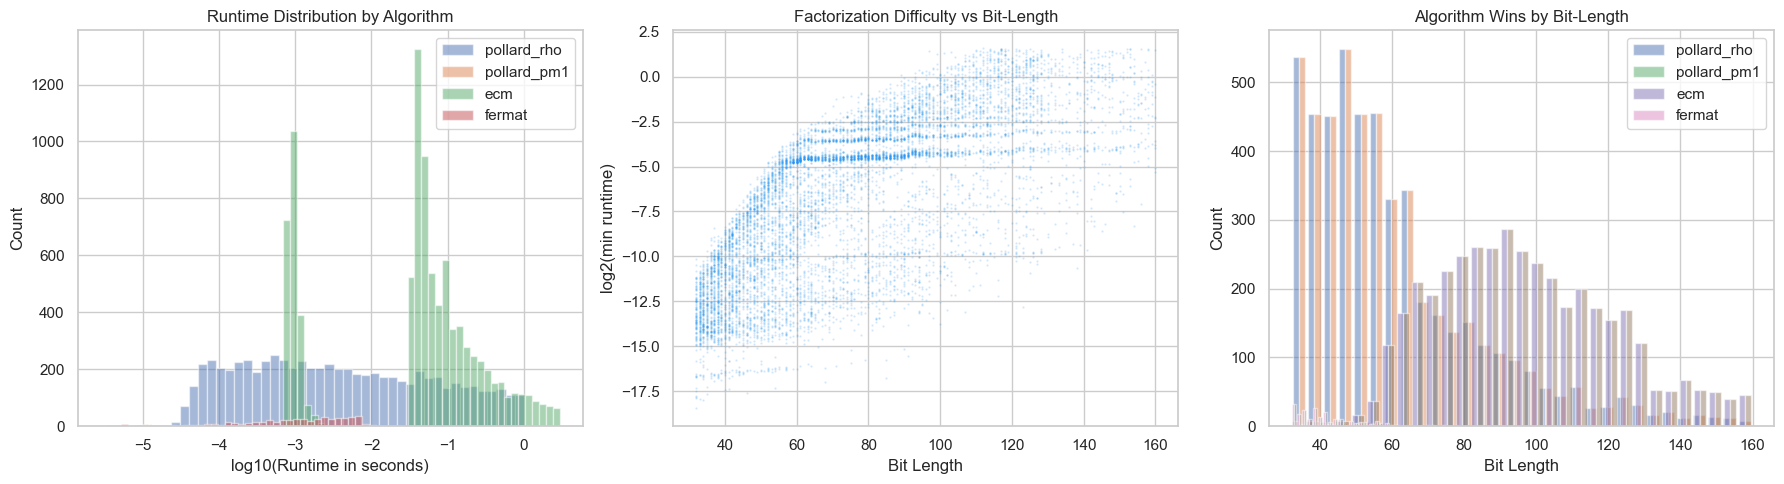


Figure saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures\03_benchmark_results.png

  PHASE 1 COMPLETE
  Total semiprimes:     10,000
  Valid for modeling:    9,367
  Features:             39
  Algorithms:           pollard_rho, pollard_pm1, ecm, fermat
  Regression target:    log_min_runtime
  Classification target: best_algorithm (4-class)
  Leakage audit:        PASS

  → Ready for Notebook 02: Model Training
  [MEM] final: 299.0 MB


In [19]:
print_section("PHASE 1.6 — Final Validation")

algo_list = ["pollard_rho", "pollard_pm1", "ecm", "fermat"]

# ─── 1. Algorithm win distribution ───────────────────────
print("1. Algorithm Win Distribution:")
print(df_final["best_algorithm"].value_counts())
total_valid = (df_final["best_algorithm"] != "none").sum()
total_none = (df_final["best_algorithm"] == "none").sum()
print(f"\n   Valid samples: {total_valid:,}")
print(f"   Failed (none): {total_none:,}")

# ─── 2. Per-algorithm success rates ─────────────────────
print("\n2. Per-Algorithm Success Rates:")
for a in algo_list:
    col_success = f"success_{a}"
    col_runtime = f"runtime_{a}"
    if col_success in df_final.columns:
        sr = df_final[col_success].mean() * 100
        mask = df_final[col_success] == True
        mt = df_final.loc[mask, col_runtime].mean() if mask.any() else 0
        print(f"   {a:>15s}: {sr:5.1f}% success, mean runtime {mt:.4f}s")

# ─── 3. Filter to valid samples only ────────────────────
valid = df_final[df_final["best_algorithm"] != "none"].copy()
print(f"\n3. Samples used for modeling: {len(valid):,} / {len(df_final):,}")

# ─── 4. Baseline R² check ───────────────────────────────
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

y = valid["log_min_runtime"].values
available_features = [f for f in feature_names if f in valid.columns]

X_bl = valid[["bit_length"]].values
r2_bl = r2_score(y, LinearRegression().fit(X_bl, y).predict(X_bl))

X_all = valid[available_features].values
r2_all = r2_score(y, LinearRegression().fit(X_all, y).predict(X_all))

print(f"\n4. Baseline R² on ACTUAL Runtimes (Anti-Circularity Check):")
print(f"   bit_length alone:     R² = {r2_bl:.4f}")
print(f"   All {len(available_features)} features (LR): R² = {r2_all:.4f}")
print(f"   ML improvement room:  {r2_all - r2_bl:.4f}")
if r2_all - r2_bl > 0.01:
    print(f"   → Structural features ADD genuine value beyond size alone.")
else:
    print(f"   → Small gap — algorithm SELECTION (classification) will be the stronger contribution.")

# ─── 5. Plots (matplotlib 3.10+ safe) ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Runtime distribution by algorithm
for a in algo_list:
    col_s = f"success_{a}"
    col_r = f"runtime_{a}"
    if col_s in df_final.columns:
        mask = df_final[col_s] == True
        if mask.any():
            runtime_vals = df_final.loc[mask, col_r].values
            log_vals = np.log10(np.clip(runtime_vals, 1e-9, None))
            axes[0].hist(log_vals, bins=40, alpha=0.5, label=a)
axes[0].set_xlabel("log10(Runtime in seconds)")
axes[0].set_ylabel("Count")
axes[0].set_title("Runtime Distribution by Algorithm")
axes[0].legend()

# Plot 2: Difficulty vs bit-length
bit_arr = valid["bit_length"].values.astype(float)
runtime_arr = valid["log_min_runtime"].values.astype(float)
axes[1].plot(bit_arr, runtime_arr, ".", markersize=1, alpha=0.1, color="#2196F3")
axes[1].set_xlabel("Bit Length")
axes[1].set_ylabel("log2(min runtime)")
axes[1].set_title("Factorization Difficulty vs Bit-Length")

# Plot 3: Algorithm wins by bit-length
for a in algo_list:
    sub = df_final[df_final["best_algorithm"] == a]
    if len(sub) > 0:
        axes[2].hist(sub["bit_length"].values, bins=30, alpha=0.5, label=a)
axes[2].set_xlabel("Bit Length")
axes[2].set_ylabel("Count")
axes[2].set_title("Algorithm Wins by Bit-Length")
axes[2].legend()

plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "03_benchmark_results.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"\nFigure saved: {RESULTS_FIG / '03_benchmark_results.png'}")

# ─── 6. Summary ─────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  PHASE 1 COMPLETE")
print(f"{'='*60}")
print(f"  Total semiprimes:     {len(df_final):,}")
print(f"  Valid for modeling:    {len(valid):,}")
print(f"  Features:             {len(available_features)}")
print(f"  Algorithms:           {', '.join(algo_list)}")
print(f"  Regression target:    log_min_runtime")
print(f"  Classification target: best_algorithm (4-class)")
print(f"  Leakage audit:        PASS")
print(f"{'='*60}")
print(f"\n  → Ready for Notebook 02: Model Training")

log_memory("final")